# Assignment: Detecting faulty pumps with k-Nearest Neighbors (k = 3)

**Introduction to Machine Learning · Automation Engineering**

**Name:** _your name_  
**Student number:** _your number_

A factory monitors 300 water pumps with three sensors: **vibration** (mm/s), **temperature** (°C) and **motor current** (A). Each pump is labelled `Normal` or `Faulty`. Your job: build a k-NN model with **k = 3** that predicts whether a pump is faulty.

Fill in every cell marked `# TODO`. Replace each `...` with your code. Then run **Kernel → Restart & Run All** and check that the notebook runs from top to bottom without errors.

## Part 0 · Setup (run this cell, do not change it)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Finds the data folder whether you run this from starter/, your submission folder, or the repo root.
# On Google Colab: upload pump_data.csv and new_pumps.csv next to this notebook.
DATA = next((p for p in [Path('.'), Path('data'), Path('../data'), Path('../../data')]
             if (p / 'pump_data.csv').exists()), None)
assert DATA is not None, 'pump_data.csv not found: check where you saved the notebook'

FEATURES = ['vibration_mm_s', 'temperature_c', 'current_a']
print('Data folder:', DATA.resolve())

Data folder: /content


## Part 1 · Explore the data (15 points)

1. Load `pump_data.csv` into a DataFrame called `df`.
2. Show the first 5 rows and the number of rows and columns.
3. Count how many pumps are `Normal` and how many are `Faulty`.

In [9]:
# TODO: load the data and look at it
# done
df = pd.read_csv("pump_data.csv")



In [16]:
# TODO: count Normal and Faulty pumps
# done
print(df["status"].value_counts())

# first 5 rows and the number of rows and columns
print(df.head())
print("Shape (rows, columns):", df.shape)

status
Normal    210
Faulty     90
Name: count, dtype: int64
  pump_id  vibration_mm_s  temperature_c  current_a  status
0    P001            2.73           69.1      11.86  Normal
1    P002            3.09           65.3       7.93  Normal
2    P003            1.69           51.5      10.80  Normal
3    P004            3.78           74.1       9.58  Faulty
4    P005            1.90           53.9      12.18  Normal
Shape (rows, columns): (300, 5)


4. Make a scatter plot of **vibration (x-axis)** against **temperature (y-axis)**, with Normal and Faulty pumps in different colours. Add axis labels and a legend.

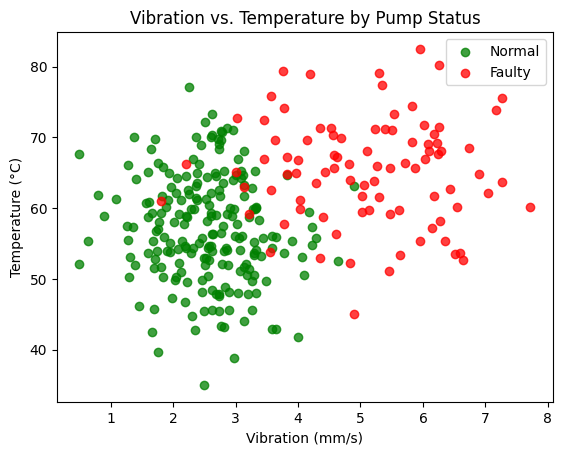

In [18]:
# TODO: scatter plot
# Hint: loop over the two classes and call plt.scatter(...) once for each
# done

import matplotlib.pyplot as plt

for status, color in [("Normal", "green"), ("Faulty", "red")]:
  subset = df[df["status"] == status]
  plt.scatter(
      subset["vibration_mm_s"],
      subset["temperature_c"],
      c=color,
      label=status,
      alpha=0.75,
  )

plt.xlabel("Vibration (mm/s)")
plt.ylabel("Temperature (°C)")
plt.title("Vibration vs. Temperature by Pump Status")
plt.legend()
plt.show()


## Part 2 · Prepare the data (15 points)

1. Put the three sensor columns (`FEATURES`) in `X` and the `status` column in `y`.
2. Split into 80% training and 20% test data. **Use `test_size=0.2, random_state=42, stratify=y`** so everyone gets the same split.
3. Scale the features with `MinMaxScaler`. **Fit the scaler on the training data only**, then transform both training and test data.

In [26]:
# TODO: features and target
# done
X = df[["vibration_mm_s", "temperature_c", "current_a"]]
y = df["status"]


In [31]:
# TODO: train/test split
X_train, X_test, y_train, y_test = ...


In [30]:
# TODO: scale the features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Part 3 · Train the model (20 points)

Create a `KNeighborsClassifier` with **`n_neighbors=3`** and train it on the scaled training data.

In [34]:
# TODO: create and train the k-NN model

from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train_scaled, y_train)



KNeighborsClassifier(n_neighbors=3)

## Part 4 · Evaluate the model (20 points)

1. Predict the test set and print the **accuracy**.
2. Show the **confusion matrix** (use `ConfusionMatrixDisplay.from_predictions`).

In [38]:
# TODO: accuracy
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.9333333333333333


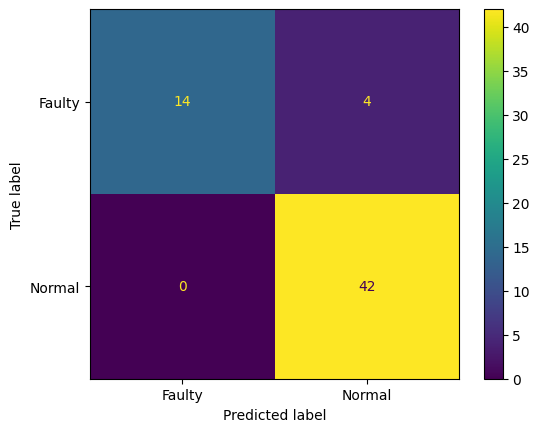

In [39]:
# TODO: confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

## Part 5 · Predict new pumps (10 points)

`new_pumps.csv` contains 3 pumps the model has never seen. Predict whether each one is Normal or Faulty.

**Remember:** new data must be scaled with the *same* scaler before predicting.

In [41]:
# TODO: predict the three new pumps
new = pd.read_csv(DATA / 'new_pumps.csv')

new_scaled = scaler.transform(new[["vibration_mm_s", "temperature_c", "current_a"]])
new["predicted_status"] = model.predict(new_scaled)
print(new[["pump_id", "predicted_status"]])


  pump_id predicted_status
0    NEW1           Normal
1    NEW2           Faulty
2    NEW3           Normal


## Part 6 · Short answers (20 points)

Answer the questions in your **`answers.md`** file (not here).

## Bonus · Which k is best? (+10 points)

1. Train models with k = 1, 3, 5, 7, 9, 11, 13, 15 and plot test accuracy against k.
2. Train k = 3 **without** scaling and compare its accuracy with your scaled model.

In [ ]:
# BONUS (optional)
